# Fairness statistics checks

Worked statistical examples for HealthEquity Agent. Run the notebook from top to bottom with the project `.venv` kernel.

| Question | Method |
|---|---|
| Do two groups have different rates when the normal approximation is suitable? | Two-proportion z-test |
| Are the rates different across several groups when expected cell counts are sufficient? | Pearson chi-square test |
| Are rates different in a sparse two-group table? | Fisher's exact test |
| How much sampling uncertainty is there in the observed fairness gaps? | Stratified percentile bootstrap |

The permutation section illustrates an alternative way to estimate a null p-value. The bootstrap section instead estimates confidence intervals by resampling within the observed groups. The examples assume independent observations. Repeated stays for the same patient may require patient-level methods in a real audit.


In [1]:
from math import sqrt

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2, fisher_exact, norm


## 1. Two-proportion z-test

Group A has 40 positive predictions out of 100, and B has 60 out of 100. Under the null hypothesis of equal rates, the pooled estimate is `(40 + 60) / (100 + 100) = 0.50`. Use it to estimate the standard error of the difference under the null. Divide the observed signed difference by that standard error, then count both tails of the standard normal distribution.


In [2]:
x_a = 40   # Positive predictions in group A
n_a = 100  # Total observations in group A

x_b = 60   # Positive predictions in group B
n_b = 100  # Total observations in group B


In [3]:
def pooled_proportion(x_a, n_a, x_b, n_b):
    return (x_a + x_b) / (n_a + n_b)


def standard_error(p, n_a, n_b):
    return sqrt(p * (1 - p) * ((1 / n_a) + (1 / n_b)))


def z_score(p_a, p_b, se):
    return (p_a - p_b) / se


def two_sided_p_value(z):
    return 2 * norm.sf(abs(z))


def two_proportion_z_test(x_a, n_a, x_b, n_b):
    p_a = x_a / n_a
    p_b = x_b / n_b
    pooled_p = pooled_proportion(x_a, n_a, x_b, n_b)
    se = standard_error(pooled_p, n_a, n_b)
    z = z_score(p_a, p_b, se)
    p_value = two_sided_p_value(z)
    return z, p_value


In [4]:
z, p_value = two_proportion_z_test(x_a, n_a, x_b, n_b)
alpha = 0.05

print(f"z = {z:.4f}")
print(f"p-value = {p_value:.6f}")
if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to reject H0")

assert np.isclose(z, -2.8284271247)
assert np.isclose(p_value, 0.004677735)


z = -2.8284
p-value = 0.004678
Reject H0


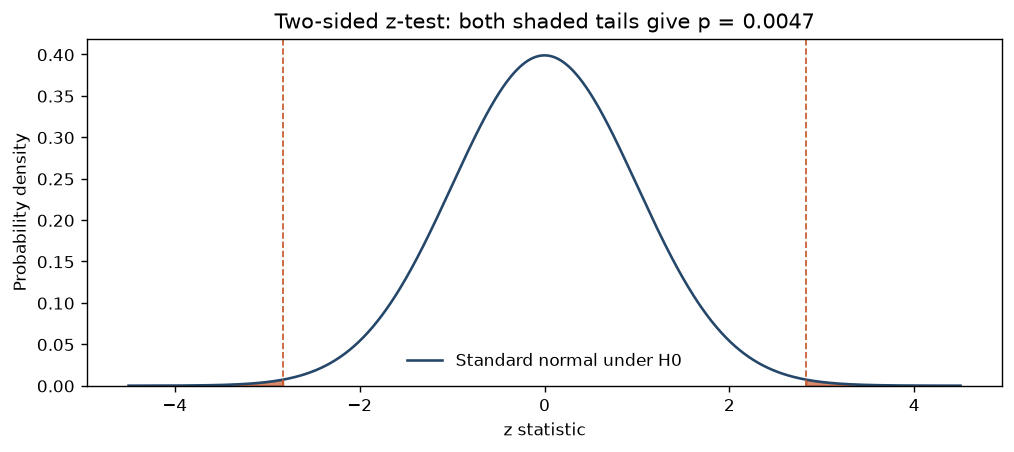

In [5]:
# Shade both tails used in the two-sided p-value.
z_grid = np.linspace(-4.5, 4.5, 901)
normal_density = norm.pdf(z_grid)
z_cutoff = abs(z)
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(z_grid, normal_density, color="#25476a", label="Standard normal under H0")
for tail in (z_grid <= -z_cutoff, z_grid >= z_cutoff):
    ax.fill_between(z_grid, normal_density, where=tail, color="#c65a2e", alpha=0.7)
for cutoff in (-z_cutoff, z_cutoff):
    ax.axvline(cutoff, color="#c65a2e", linestyle="--", linewidth=1)
ax.set(
    title=f"Two-sided z-test: both shaded tails give p = {p_value:.4f}",
    xlabel="z statistic",
    ylabel="Probability density",
    ylim=(0, None),
)
ax.legend(frameon=False)
plt.show()


## 2. Pearson chi-square test

Add a third group, C, with 50 positive predictions out of 100. The null hypothesis is that all groups have the same positive prediction rate. Keep each group's total fixed and multiply it by the pooled rate to get its expected positive count. Each cell contributes `(observed - expected)**2 / expected`, which is the squared Pearson residual. With two outcome columns, the degrees of freedom are the number of groups minus one. Large statistics count toward the right-tail p-value.


In [6]:
def chi_square(positive_counts, totals):
    pooled_rate = sum(positive_counts) / sum(totals)

    expected_positive_counts = [total * pooled_rate for total in totals]
    expected_negative_counts = [
        total - expected
        for total, expected in zip(totals, expected_positive_counts)
    ]
    observed_negative_counts = [
        total - positive
        for total, positive in zip(totals, positive_counts)
    ]

    chi_square_stat = 0.0

    for obs_pos, exp_pos, obs_neg, exp_neg in zip(
        positive_counts,
        expected_positive_counts,
        observed_negative_counts,
        expected_negative_counts,
    ):
        residual_pos = (obs_pos - exp_pos) / sqrt(exp_pos)
        residual_neg = (obs_neg - exp_neg) / sqrt(exp_neg)
        chi_square_stat += residual_pos**2 + residual_neg**2

    df = len(totals) - 1
    p_value = chi2.sf(chi_square_stat, df)

    return chi_square_stat, df, p_value


In [7]:
stat, df, p_value = chi_square([40, 60, 50], [100, 100, 100])

print(f"Chi-square statistic: {stat:.2f}")
print(f"Degrees of freedom: {df}")
print(f"P-value: {p_value:.4f}")
assert np.isclose(stat, 8.0)
assert df == 2
assert np.isclose(p_value, 0.018315639)


Chi-square statistic: 8.00
Degrees of freedom: 2
P-value: 0.0183


### comparison: permutation test

Shuffle the pooled predictions and divide them into groups of their original sizes. Recompute chi-square for each shuffle and count how many statistics equal or exceed the observed value. This estimates the null p-value by randomizing group assignments under the assumption that observations are exchangeable under the null.


In [8]:
def permutation_test(positive_counts, totals, n_shuffles=10000, seed=42):
    rng = np.random.default_rng(seed)

    observed_stat, _, _ = chi_square(positive_counts, totals)

    total_positive = sum(positive_counts)
    total_negative = sum(totals) - total_positive
    box = np.array([1] * total_positive + [0] * total_negative)

    split_points = np.cumsum(totals)[:-1]
    as_extreme = 0
    shuffled_statistics = []

    for _ in range(n_shuffles):
        shuffled = rng.permutation(box)
        groups = np.split(shuffled, split_points)
        shuffled_positive = [int(group.sum()) for group in groups]

        shuffled_stat, _, _ = chi_square(shuffled_positive, totals)
        shuffled_statistics.append(shuffled_stat)

        if shuffled_stat >= observed_stat or np.isclose(
            shuffled_stat, observed_stat, rtol=0, atol=1e-12
        ):
            as_extreme += 1

    permutation_p_value = (as_extreme + 1) / (n_shuffles + 1)
    return observed_stat, permutation_p_value, shuffled_statistics


In [9]:
observed_stat, permutation_p_value, shuffled_statistics = permutation_test(
    [40, 60, 50],
    [100, 100, 100],
)

print(f"Observed chi-square: {observed_stat:.2f}")
print(f"Permutation p-value: {permutation_p_value:.4f}")


Observed chi-square: 8.00
Permutation p-value: 0.0203


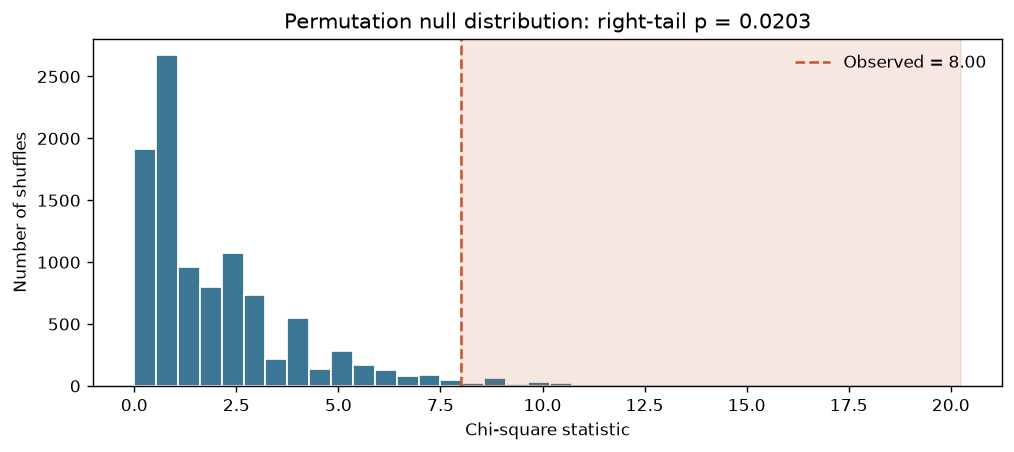

In [10]:
# Compare the observed statistic with the shuffled null distribution.
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.hist(shuffled_statistics, bins=36, color="#3b7695", edgecolor="white")
ax.axvspan(observed_stat, ax.get_xlim()[1], color="#c65a2e", alpha=0.14)
ax.axvline(observed_stat, color="#c65a2e", linestyle="--", label=f"Observed = {observed_stat:.2f}")
ax.set(
    title=f"Permutation null distribution: right-tail p = {permutation_p_value:.4f}",
    xlabel="Chi-square statistic",
    ylabel="Number of shuffles",
)
ax.legend(frameon=False)
plt.show()


## 3. Fisher's exact test

Compare TPR for Asian and Hispanic stays in the audit sample. The denominator is the number of actual readmissions in each group, so the columns are true positives (TP) and false negatives (FN). Under equal TPR, the expected Asian TP count is `14 * (6 + 8) / (14 + 26) = 4.9`. The test-selection rule routes sparse comparisons to Fisher's test when an expected count is below 5. This example uses a two-sided 2-by-2 test.


In [11]:
# Rows: Asian, Hispanic
# Columns: detected readmissions (TP), missed readmissions (FN)
table = [
    [6, 8],
    [8, 18],
]

result = fisher_exact(table, alternative="two-sided")
print(f"Fisher p-value: {result.pvalue:.4f}")
assert np.isclose(result.pvalue, 0.5013, atol=0.00005)


Fisher p-value: 0.5013


## 4. Bootstrap confidence intervals

### 4.1 Calculate the observed DPD

Demographic parity difference (DPD) is the highest group selection rate minus the lowest. The observed rates are 40% and 60%, so the observed gap is 20 percentage points. The bootstrap keeps these observed group distributions as its starting point. A pooled rate of 50% belongs to the equal-rates null hypothesis used above.


In [12]:
bootstrap_positive_counts = [40, 60]
bootstrap_totals = [100, 100]

selection_rates = [
    positives / total
    for positives, total in zip(bootstrap_positive_counts, bootstrap_totals)
]
observed_dpd = max(selection_rates) - min(selection_rates)

print(f"Selection rates: {selection_rates}")
print(f"Observed DPD: {observed_dpd:.2f} ({observed_dpd * 100:.0f} percentage points)")


Selection rates: [0.4, 0.6]
Observed DPD: 0.20 (20 percentage points)


### 4.2 Draw one resample

Represent each prediction as 1 (positive) or 0 (negative). Draw 100 observations from A and 100 from B, separately and with replacement. A row can appear more than once, and other rows may be absent. The group sizes stay fixed, while their selection rates and gap can change.


In [13]:
bootstrap_rng = np.random.default_rng(42)
bootstrap_groups = [
    np.repeat([1, 0], [positives, total - positives])
    for positives, total in zip(bootstrap_positive_counts, bootstrap_totals)
]

resampled_groups = [
    bootstrap_rng.choice(group, size=len(group), replace=True)
    for group in bootstrap_groups
]
resampled_rates = [float(group.mean()) for group in resampled_groups]
resampled_dpd = max(resampled_rates) - min(resampled_rates)

print(f"Resampled selection rates: {resampled_rates}")
print(f"Observed DPD: {observed_dpd:.2f}")
print(f"Resampled DPD: {resampled_dpd:.2f}")


Resampled selection rates: [0.33, 0.62]
Observed DPD: 0.20
Resampled DPD: 0.29


### 4.3 Repeat 1,000 times and read the interval

Save the DPD from every draw. The 2.5th and 97.5th percentiles of those 1,000 values give the percentile 95% confidence interval. Reinitialize the generator with seed 42 so the whole sequence is reproducible and starts with the example draw above.


In [14]:
n_resamples = 1_000
bootstrap_seed = 42
dpd_rng = np.random.default_rng(bootstrap_seed)
dpd_draws = []

for _ in range(n_resamples):
    rates = []
    for group in bootstrap_groups:
        sampled_predictions = dpd_rng.choice(group, size=len(group), replace=True)
        rates.append(sampled_predictions.mean())
    dpd_draws.append(max(rates) - min(rates))

assert len(dpd_draws) == n_resamples
assert np.isclose(dpd_draws[0], resampled_dpd)
dpd_lower, dpd_upper = np.percentile(dpd_draws, [2.5, 97.5])
print(f"Observed DPD: {observed_dpd:.3f}")
print(f"95% bootstrap CI: [{dpd_lower:.3f}, {dpd_upper:.3f}]")


Observed DPD: 0.200
95% bootstrap CI: [0.060, 0.330]


### 4.4 Bootstrap all three fairness gaps together

DPD uses predictions alone. Equalized odds and PPV also need the ground truth, so resample each `(outcome, prediction)` row together. The synthetic groups below keep the 40% and 60% selection rates and provide all four confusion matrix counts.

| Group | TP | FN | FP | TN |
|---|---:|---:|---:|---:|
| A | 20 | 20 | 20 | 40 |
| B | 32 | 8 | 28 | 32 |

For each resample, compute the group rates, then calculate DPD from selection rates, equalized odds difference from the larger of the TPR and FPR gaps, and PPV difference from the PPV gap. A gap is unavailable for a draw if a required group rate has a zero denominator. The interval summary counts valid draws separately for each metric.


In [15]:
# Each row pairs the true outcome with the predicted label.
paired_groups = [
    np.repeat([[1, 1], [1, 0], [0, 1], [0, 0]], counts, axis=0)
    for counts in ([20, 20, 20, 40], [32, 8, 28, 32])
]


def group_rates(rows):
    outcome = rows[:, 0]
    prediction = rows[:, 1]
    actual_positive = outcome == 1
    actual_negative = outcome == 0
    predicted_positive = prediction == 1

    return {
        "selection_rate": prediction.mean(),
        "tpr": prediction[actual_positive].mean() if actual_positive.any() else np.nan,
        "fpr": prediction[actual_negative].mean() if actual_negative.any() else np.nan,
        "ppv": outcome[predicted_positive].mean() if predicted_positive.any() else np.nan,
    }


def fairness_gaps(groups):
    rates = [group_rates(group) for group in groups]

    def gap(rate):
        values = np.array([group[rate] for group in rates])
        return np.max(values) - np.min(values)

    return {
        "DPD": gap("selection_rate"),
        "Equalized odds difference": np.maximum(gap("tpr"), gap("fpr")),
        "PPV difference": gap("ppv"),
    }


def bootstrap_gap_draws(groups, n_resamples, seed):
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_resamples):
        resampled = []
        for group in groups:
            row_indices = rng.integers(0, len(group), size=len(group))
            resampled.append(group[row_indices])
        draws.append(fairness_gaps(resampled))
    return draws


In [16]:
observed_gaps = fairness_gaps(paired_groups)
assert np.isclose(observed_gaps["DPD"], 0.20)
assert np.isclose(observed_gaps["Equalized odds difference"], 0.30)
assert np.isclose(observed_gaps["PPV difference"], 32 / 60 - 20 / 40)

gap_draws = bootstrap_gap_draws(paired_groups, n_resamples, bootstrap_seed)
assert len(gap_draws) == n_resamples

for metric, observed in observed_gaps.items():
    values = np.array([draw[metric] for draw in gap_draws])
    valid = values[np.isfinite(values)]
    if len(valid) == 0:
        print(f"{metric}: observed={observed:.3f}, interval unavailable (no valid draws)")
        continue
    lower, upper = np.percentile(valid, [2.5, 97.5])
    print(
        f"{metric}: observed={observed:.3f}, 95% CI=[{lower:.3f}, {upper:.3f}], "
        f"valid draws={len(valid)}/{n_resamples}"
    )


DPD: observed=0.200, 95% CI=[0.060, 0.330], valid draws=1000/1000
Equalized odds difference: observed=0.300, 95% CI=[0.130, 0.498], valid draws=1000/1000
PPV difference: observed=0.033, 95% CI=[0.003, 0.246], valid draws=1000/1000


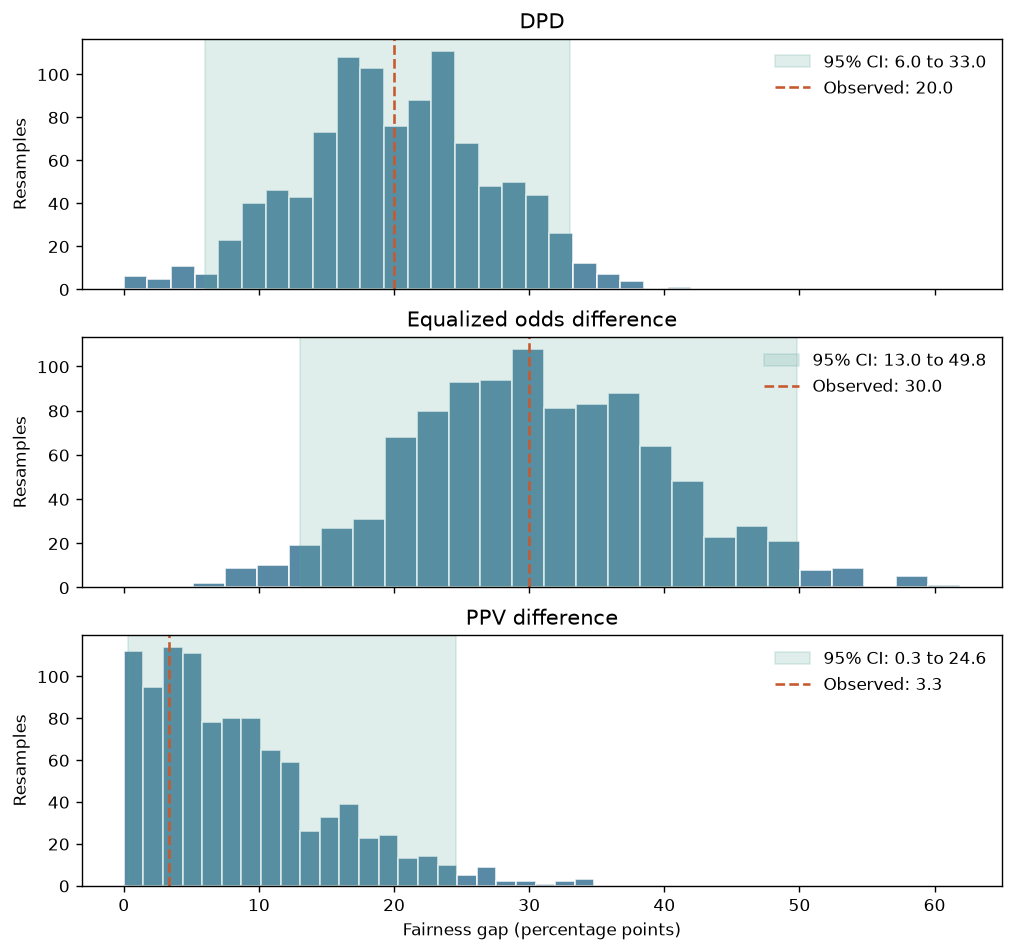

In [17]:
# Each histogram shows how the gap varied across bootstrap resamples.
fig, axes = plt.subplots(3, 1, figsize=(8, 7.5), sharex=True, layout="constrained")
for ax, (metric, observed) in zip(axes, observed_gaps.items()):
    values = np.array([draw[metric] for draw in gap_draws])
    valid = 100 * values[np.isfinite(values)]
    ax.set(title=metric, ylabel="Resamples")
    if not len(valid):
        ax.text(0.5, 0.5, "No valid resamples", ha="center", transform=ax.transAxes)
        continue
    lower, upper = np.percentile(valid, [2.5, 97.5])
    ax.hist(valid, bins=24, color="#3b7695", edgecolor="white", alpha=0.85)
    ax.axvspan(lower, upper, color="#58a595", alpha=0.18, label=f"95% CI: {lower:.1f} to {upper:.1f}")
    ax.axvline(100 * observed, color="#c65a2e", linestyle="--", label=f"Observed: {100 * observed:.1f}")
    ax.legend(frameon=False, loc="upper right")
axes[-1].set_xlabel("Fairness gap (percentage points)")
plt.show()


## 5. Interpret the results

A p-value is the probability, under the null hypothesis and test assumptions, of a test statistic at least as extreme as the observed statistic. A bootstrap interval estimates sampling uncertainty in the observed gap under the resampling scheme. Read the gap, its interval, and the valid resample count together. Absolute and maximum gaps are nonnegative, so these percentile intervals should not be used as a replacement for hypothesis tests of equal rates.

These cells show the calculations underlying the shared functions in `fairness/stats.py`. Automated checks are in `test/test_stats.py`; group eligibility and severity rules are defined in `fairness/policy.py` and tested in `test/test_policy.py`. The permutation example illustrates an alternative null simulation rather than the engine's automatic test-selection path.

The notebook demonstrates statistical calculations rather than an integrated audit report. Apply eligibility filtering before reportable comparisons. Severity labels describe the configured gap-and-interval policy and are separate from significance-test results. [Methodology](../docs/methodology.md) records the formulas, assumptions, and limitations.
